# Person 2: Gradient-Boosted Trees, Logistic Regression and Rankings

This notebook uses the cleaned weekly Google Trends data to:

1. build the input features and targets for 4- and 8-week forecasts,
2. tune LightGBM (gradient-boosted trees) and logistic regression on the three validation years (2022, 2023, 2024),
3. run the final test (January 2025 onwards) with 5 random seeds, retraining every 4 weeks,
4. compare the results with Person 1's models,
5. save predictions, tuning results, weekly rankings for the app, feature importance (SHAP) and forecast graphs.

All outputs go to results/google_trends/.

**Predictions format**: date, item, horizon, actual, predicted, model, period, last4_avg,
plus predicted_rising, actually_rose, seed, prob_rising.
- date = the week the forecast was made
- actual, predicte = average over the 4 weeks ending horizon weeks after date
- last4_avg = average of the 4 weeks up to and including date

In [46]:
!pip install lightgbm scikit-learn openpyxl -q

In [47]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

## 1. Settings

- THRESHOLD: a style is "rising" when its next 4-week average / last 4-week average is above this value (team decision: 1.1 or 1.2).
- EPS: a small number added before dividing, so that weeks with 0 searches do not cause division by zero.
- MIN_LEVEL: weeks where the last 4-week average is below this are skipped (growth on almost zero searches is meaningless).
- QUICK_RUN = True: a fast check with 1 seed and fewer refits. Set to False for the real results.

In [48]:
DATA_FILE = "raw_pulls/trends_weekly_clean.csv"      # weekly table: rows = weeks, columns = keywords
KEYWORDS_FILE = "google_trends_keywords.xlsx"   # sheet "Keywords", columns "Keyword" and "Category"
OUT_DIR = "results/google_trends"
FIG_DIR = os.path.join(OUT_DIR, "figures")

HORIZONS = [4, 8]
THRESHOLD = 1.2
EPS = 1.0
MIN_LEVEL = 5.0
TOP_K = [5, 10, 20]

# validation years (used for tuning) and the final test period
FOLDS = {
    "val_2022": ("2022-01-01", "2022-12-31"),
    "val_2023": ("2023-01-01", "2023-12-31"),
    "val_2024": ("2024-01-01", "2024-12-31"),
}
TEST_START = "2025-01-01"

QUICK_RUN = False
SEEDS = [0] if QUICK_RUN else [0, 1, 2, 3, 4]
REFIT_EVERY_TEST = 13 if QUICK_RUN else 4      # weeks between retraining in the final test

os.makedirs(FIG_DIR, exist_ok=True)

## 2. Load the data

In [49]:
wide = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True).sort_index()
kw_df = pd.read_excel(KEYWORDS_FILE, sheet_name="Keywords")
category = dict(zip(kw_df["Keyword"], kw_df["Category"]))

print(f"{wide.shape[0]} weeks x {wide.shape[1]} keywords, "
      f"{wide.index.min().date()} to {wide.index.max().date()}")
missing_cat = [c for c in wide.columns if c not in category]
print("Keywords without a category:", missing_cat)

489 weeks x 134 keywords, 2017-06-04 to 2026-10-11
Keywords without a category: []


## 3. Features and targets

Every keyword has its own 0-100 scale, so all inputs are expressed **relative to the keyword's last 4-week average**,
as log ratios: log((a + EPS) / (b + EPS)). A value of 0 means "the same as the last 4 weeks", positive means higher.

The model predicts the same kind of ratio for the future 4-week average, which is then converted back
to the keyword's own scale.

All features use only weeks up to and including the forecast week.

In [50]:
def logratio(a, b):
    return np.log((a + EPS) / (b + EPS))

last4 = wide.rolling(4).mean()          # average of the last 4 weeks (t-3 .. t)

feats = {}
for k in [0, 1, 2, 4, 8, 12, 26]:       # recent history: value k weeks ago vs. the last 4 weeks
    feats[f"lag{k}"] = logratio(wide.shift(k), last4)
for k in [4, 8, 12]:                    # momentum: last 4 weeks vs. the 4 weeks that ended k weeks earlier
    feats[f"growth{k}"] = logratio(last4, last4.shift(k))
feats["accel"] = feats["growth4"] - feats["growth4"].shift(4)          # is growth speeding up?
feats["vol8"] = wide.rolling(8).std() / (last4 + EPS)                  # volatility
feats["vol26"] = wide.rolling(26).std() / (wide.rolling(26).mean() + EPS)
feats["lag52"] = logratio(wide.shift(52), last4)                       # same week last year
for h in HORIZONS:                       # how much the style grew over the same h weeks one year earlier
    feats[f"last_year_growth{h}"] = logratio(last4.shift(52 - h), last4.shift(52))

market_g4 = feats["growth4"].mean(axis=1)                              # average growth of all styles
feats["market_growth4"] = pd.DataFrame({c: market_g4 for c in wide.columns})
feats["rel_growth4"] = feats["growth4"].sub(market_g4, axis=0)         # growth compared with the market

# turn every (weeks x keywords) table into one long table: one row per (date, item)
idx = pd.MultiIndex.from_product([wide.index, wide.columns], names=["date", "item"])
table = pd.DataFrame({name: f.reindex(index=wide.index, columns=wide.columns).to_numpy().ravel()
                      for name, f in feats.items()}, index=idx)
table["last4_avg"] = last4.to_numpy().ravel()
table["last_value"] = wide.to_numpy().ravel()
for h in HORIZONS:                       # target: average of the 4 weeks ending h weeks after the date
    table[f"actual_h{h}"] = last4.shift(-h).to_numpy().ravel()
table = table.reset_index()

week = table["date"].dt.isocalendar().week.astype(float)
table["week_sin"] = np.sin(2 * np.pi * week / 52)
table["week_cos"] = np.cos(2 * np.pi * week / 52)
table["category"] = pd.Categorical(table["item"].map(category).fillna("Unknown"))

NUM_FEATURES = list(feats.keys()) + ["week_sin", "week_cos"]
LGBM_FEATURES = NUM_FEATURES + ["category"]
LOGIT_FEATURES = NUM_FEATURES

print(table.shape)
table.head()

(65526, 27)


,date,item,lag0,lag1,lag2,lag4,lag8,lag12,lag26,growth4,...,last_year_growth8,market_growth4,rel_growth4,last4_avg,last_value,actual_h4,actual_h8,week_sin,week_cos,category
0,2017-06-04,skinny jeans,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,16.463153,17.002928,19.027086,0.464723,-0.885456,Jeans and denim
1,2017-06-04,wide leg jeans,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.990721,0.908161,0.963201,0.464723,-0.885456,Jeans and denim
2,2017-06-04,baggy jeans,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.280813,1.200762,1.307497,0.464723,-0.885456,Jeans and denim
3,2017-06-04,straight leg jeans,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.959641,1.779148,1.933857,0.464723,-0.885456,Jeans and denim
4,2017-06-04,bootcut jeans,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,5.369217,5.053381,6.158808,0.464723,-0.885456,Jeans and denim


In [51]:
def rows_for(h):
    """All usable rows for horizon h, with the target and the rising label."""
    d = table.dropna(subset=NUM_FEATURES).copy()
    d = d[d["last4_avg"] >= MIN_LEVEL]
    d["horizon"] = h
    d["actual"] = d[f"actual_h{h}"]
    d["target"] = logratio(d["actual"], d["last4_avg"])
    d["actually_rose"] = d["actual"] > THRESHOLD * d["last4_avg"]
    d["target_date"] = d["date"] + pd.Timedelta(weeks=h)   # when the answer becomes known
    return d.reset_index(drop=True)

data = {h: rows_for(h) for h in HORIZONS}
for h in HORIZONS:
    known = data[h]["actual"].notna()
    print(f"h={h}: {len(data[h])} rows, share rising = {data[h].loc[known, 'actually_rose'].mean():.3f}")

h=4: 51579 rows, share rising = 0.117
h=8: 51579 rows, share rising = 0.207


## 4. Walk-forward training

At each refit date T the model is trained only on rows whose answer was already known at T
(target_date <= T), then it forecasts the next block of weeks. This keeps future information out of training.

In [52]:
def walk_forward(d, start, end, refit_every, fit_predict):
    dates = sorted(d.loc[(d["date"] >= start) & (d["date"] <= end), "date"].unique())
    out = []
    for i in range(0, len(dates), refit_every):
        block = dates[i:i + refit_every]
        T = block[0]
        train = d[(d["target_date"] <= T) & d["actual"].notna()]
        test = d[d["date"].isin(block)]
        out.append(fit_predict(train, test))
    return pd.concat(out, ignore_index=True)


def lgbm_fit_predict(params, seed):
    def fp(train, test):
        model = lgb.LGBMRegressor(n_estimators=params["n_estimators"],
                                  learning_rate=params["learning_rate"],
                                  num_leaves=params["num_leaves"],
                                  min_child_samples=params["min_child_samples"],
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  random_state=seed, verbose=-1)
        model.fit(train[LGBM_FEATURES], train["target"])
        out = test.copy()
        ratio = np.exp(model.predict(test[LGBM_FEATURES]))
        out["predicted"] = (ratio * (out["last4_avg"] + EPS) - EPS).clip(lower=0)
        out["predicted_rising"] = out["predicted"] > THRESHOLD * out["last4_avg"]
        out["prob_rising"] = np.nan
        return out
    return fp


def logit_fit_predict(params):
    def fp(train, test):
        model = make_pipeline(StandardScaler(),
                              LogisticRegression(C=params["C"], class_weight="balanced", max_iter=2000))
        model.fit(train[LOGIT_FEATURES], train["actually_rose"])
        out = test.copy()
        out["prob_rising"] = model.predict_proba(test[LOGIT_FEATURES])[:, 1]
        out["predicted_rising"] = out["prob_rising"] > 0.5
        out["predicted"] = np.nan
        return out
    return fp


OUT_COLS = ["date", "item", "horizon", "actual", "predicted", "model", "period", "last4_avg",
            "predicted_rising", "actually_rose", "seed", "prob_rising"]

def finish(pred, model_name, period, seed):
    pred = pred.copy()
    pred["model"], pred["period"], pred["seed"] = model_name, period, seed
    return pred[OUT_COLS]

## 5. Metrics

The same function scores our files and Person 1's files, so the comparison is fair.
- mae: average forecast error on the keyword's own scale
- mase: our MAE divided by the MAE of the 4-week-average baseline (last4_avg); below 1 = better than that baseline
- direction_acc: share of forecasts with the right direction (up or down)
- precision, recall, f1, pr_auc: the rising label
- precision_at_K: share of the K highest-ranked styles each week that really rose

In [53]:
def evaluate(pred, by=("model", "horizon", "period")):
    p = pred[pred["actual"].notna()].copy()
    for col in ["predicted_rising", "actually_rose", "prob_rising", "seed"]:
        if col not in p:
            p[col] = np.nan
    # files without these columns: work them out from actual / predicted
    p["actually_rose"] = p["actually_rose"].where(p["actually_rose"].notna(),
                                                  p["actual"] > THRESHOLD * p["last4_avg"])
    p["predicted_rising"] = p["predicted_rising"].where(p["predicted_rising"].notna(),
                                                        p["predicted"] > THRESHOLD * p["last4_avg"])
    p["seed"] = p["seed"].fillna(0)
    p["score"] = p["prob_rising"].fillna(p["predicted"] / (p["last4_avg"] + EPS))
    rows = []
    for key, g in p.groupby(list(by)):
        r = dict(zip(by, key))
        has_value = g["predicted"].notna().all()
        if has_value:
            mae = (g["actual"] - g["predicted"]).abs().mean()
            r["mae"] = mae
            r["mase"] = mae / (g["actual"] - g["last4_avg"]).abs().mean()
            r["direction_acc"] = (np.sign(g["predicted"] - g["last4_avg"])
                                  == np.sign(g["actual"] - g["last4_avg"])).mean()
        y, yhat = g["actually_rose"].astype(bool), g["predicted_rising"].astype(bool)
        r["precision"] = precision_score(y, yhat, zero_division=0)
        r["recall"] = recall_score(y, yhat, zero_division=0)
        r["f1"] = f1_score(y, yhat, zero_division=0)
        if g["prob_rising"].notna().all() and y.nunique() == 2:
            r["pr_auc"] = average_precision_score(y, g["prob_rising"])
        for k in TOP_K:   # rank all styles each week (and seed) by predicted growth
            top = g.sort_values("score", ascending=False).groupby(["date", "seed"]).head(k)
            r[f"precision_at_{k}"] = top.groupby(["date", "seed"])["actually_rose"].mean().mean()
        r["rows"] = len(g)
        rows.append(r)
    return pd.DataFrame(rows)

## 6. Tuning on the validation years

Each setting is trained once per validation year (on all earlier data) with seed 0.
LightGBM settings are chosen by the lowest average MAE over 2022-2024,
logistic regression by the highest average PR-AUC.

In [54]:
LGBM_GRID = [dict(n_estimators=n, learning_rate=lr, num_leaves=nl, min_child_samples=mc)
             for n, lr, nl, mc in itertools.product([300], [0.03, 0.1], [15, 31], [20, 100])]
LOGIT_GRID = [dict(C=c) for c in [0.01, 0.1, 1, 10]]
if QUICK_RUN:
    LGBM_GRID, LOGIT_GRID = LGBM_GRID[:2], LOGIT_GRID[:2]

tuning_rows = []
for h in HORIZONS:
    for i, params in enumerate(LGBM_GRID):
        for fold, (start, end) in FOLDS.items():
            pred = walk_forward(data[h], start, end, 53, lgbm_fit_predict(params, seed=0))
            m = evaluate(finish(pred, "lightgbm", fold, 0)).iloc[0]
            tuning_rows.append({"model": "lightgbm", "horizon": h, "setting": i, **params,
                                "fold": fold, "mae": m["mae"], "pr_auc": np.nan, "f1": m["f1"]})
    for i, params in enumerate(LOGIT_GRID):
        for fold, (start, end) in FOLDS.items():
            pred = walk_forward(data[h], start, end, 53, logit_fit_predict(params))
            m = evaluate(finish(pred, "logistic", fold, 0)).iloc[0]
            tuning_rows.append({"model": "logistic", "horizon": h, "setting": i, **params,
                                "fold": fold, "mae": np.nan, "pr_auc": m["pr_auc"], "f1": m["f1"]})

tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(os.path.join(OUT_DIR, "tuning_results_lightgbm_logistic.csv"), index=False)

best = {}
for h in HORIZONS:
    t = tuning[tuning["horizon"] == h]
    lg = t[t["model"] == "lightgbm"].groupby("setting")["mae"].mean()
    lo = t[t["model"] == "logistic"].groupby("setting")["pr_auc"].mean()
    best[("lightgbm", h)] = LGBM_GRID[lg.idxmin()]
    best[("logistic", h)] = LOGIT_GRID[lo.idxmax()]
    print(f"h={h}: best LightGBM {best[('lightgbm', h)]} (MAE {lg.min():.2f}), "
          f"best logistic {best[('logistic', h)]} (PR-AUC {lo.max():.3f})")

h=4: best LightGBM {'n_estimators': 300, 'learning_rate': 0.03, 'num_leaves': 31, 'min_child_samples': 20} (MAE 1.42), best logistic {'C': 0.01} (PR-AUC 0.568)
h=8: best LightGBM {'n_estimators': 300, 'learning_rate': 0.03, 'num_leaves': 31, 'min_child_samples': 20} (MAE 2.15), best logistic {'C': 10} (PR-AUC 0.664)


## 7. Validation and final-test predictions with the chosen settings

- Validation years: the chosen settings, all 5 seeds (Person 5 uses these for decisions such as the threshold).
- Final test (January 2025 onwards): retrained every 4 weeks, 5 seeds. Not used for any decision.

Logistic regression gives the same result for every seed, so it is run once (seed = 0).

In [55]:
all_preds = []
for h in HORIZONS:
    d = data[h]
    for fold, (start, end) in FOLDS.items():
        for seed in SEEDS:
            pred = walk_forward(d, start, end, 53, lgbm_fit_predict(best[("lightgbm", h)], seed))
            all_preds.append(finish(pred, "lightgbm", fold, seed))
        pred = walk_forward(d, start, end, 53, logit_fit_predict(best[("logistic", h)]))
        all_preds.append(finish(pred, "logistic", fold, 0))

    test_end = d["date"].max()
    for seed in SEEDS:
        pred = walk_forward(d, TEST_START, test_end, REFIT_EVERY_TEST, lgbm_fit_predict(best[("lightgbm", h)], seed))
        all_preds.append(finish(pred, "lightgbm", "test", seed))
    pred = walk_forward(d, TEST_START, test_end, REFIT_EVERY_TEST, logit_fit_predict(best[("logistic", h)]))
    all_preds.append(finish(pred, "logistic", "test", 0))

preds = pd.concat(all_preds, ignore_index=True)

# the last weeks have no actual value yet: they are real forecasts (used for the rankings), not scored
known = preds[preds["actual"].notna()]
for name in ["lightgbm", "logistic"]:
    known[known["model"] == name].to_csv(os.path.join(OUT_DIR, f"predictions_{name}.csv"), index=False)
print(known.groupby(["model", "horizon", "period"]).size())

model     horizon  period  
lightgbm  4        test        58515
                   val_2022    32010
                   val_2023    33480
                   val_2024    33710
          8        test        55855
                   val_2022    32010
                   val_2023    33480
                   val_2024    33710
logistic  4        test        11703
                   val_2022     6402
                   val_2023     6696
                   val_2024     6742
          8        test        11171
                   val_2022     6402
                   val_2023     6696
                   val_2024     6742
dtype: int64


## 8. Scores and comparison with Person 1

Reads every predictions*.csv in results/google_trends/, including Person 1's baselines and simpler models,
and scores them all with the same function.

In [ ]:
# Person 1's predictions.csv uses a different date convention; it is compared fairly in section 14
files = [f for f in os.listdir(OUT_DIR) if f.startswith("predictions") and f.endswith(".csv")
         and f != "predictions.csv"]
everything = pd.concat([pd.read_csv(os.path.join(OUT_DIR, f), parse_dates=["date"]) for f in files],
                       ignore_index=True)
print("Files:", files)

scores = evaluate(everything)
scores.to_csv(os.path.join(OUT_DIR, "metrics_comparison.csv"), index=False)

# summary: average of the three validation years, and the final test
scores["stage"] = np.where(scores["period"] == "test", "test", "validation")
summary = scores.groupby(["stage", "horizon", "model"]).mean(numeric_only=True).round(3)
summary

Files: ['predictions.csv', 'predictions_lightgbm.csv', 'predictions_logistic.csv']


mae   mase  direction_acc  precision  \
stage      horizon model                                                     
test       4       avg_4w           9.645    NaN          0.000      0.000   
                   ets              9.004    NaN          0.000      0.000   
                   lasso           10.524    NaN          0.000      0.000   
                   last_value       8.797    NaN          0.000      0.000   
                   lightgbm         7.346  0.974          0.689      0.432   
                   logistic           NaN    NaN            NaN      0.415   
                   ridge           10.561    NaN          0.000      0.000   
                   seasonal_naive  11.450    NaN          0.000      0.000   
           8       avg_4w          12.281    NaN          0.000      0.000   
                   ets             12.708    NaN          0.000      0.000   
                   lasso           13.450    NaN          0.000      0.000   
                   last_value      12.113    NaN          0.000      0.000   
                   lightgbm        11.648  0.995          0.690      0.603   
                   logistic           NaN    NaN            NaN      0.586   
                   ridge           13.508    NaN          0.000      0.000   
                   seasonal_naive  11.451    NaN          0.000      0.000   
validation 4       avg_4w           3.258    NaN          0.000      0.000   
                   ets              2.800    NaN          0.000      0.000   
                   lasso            2.560    NaN          0.000      0.000   
                   last_value       2.839    NaN          0.000      0.000   
                   lightgbm         1.424  0.581          0.747      0.776   
                   logistic           NaN    NaN            NaN      0.352   
                   ridge            2.557    NaN          0.000      0.000   
                   seasonal_naive   4.665    NaN          0.000      0.000   
           8       avg_4w           4.590    NaN          0.000      0.000   
                   ets              4.211    NaN          0.000      0.000   
                   lasso            3.384    NaN          0.000      0.000   
                   last_value       4.293    NaN          0.000      0.000   
                   lightgbm         2.153  0.531          0.779      0.792   
                   logistic           NaN    NaN            NaN      0.494   
                   ridge            3.381    NaN          0.000      0.000   
                   seasonal_naive   4.659    NaN          0.000      0.000   

                                   recall     f1  precision_at_5  \
stage      horizon model                                           
test       4       avg_4w           0.000  0.000           0.000   
                   ets              0.000  0.000           0.000   
                   lasso            0.000  0.000           0.000   
                   last_value       0.000  0.000           0.000   
                   lightgbm         0.295  0.350           0.605   
                   logistic         0.708  0.523           0.557   
                   ridge            0.000  0.000           0.000   
                   seasonal_naive   0.000  0.000           0.000   
           8       avg_4w           0.000  0.000           0.000   
                   ets              0.000  0.000           0.000   
                   lasso            0.000  0.000           0.000   
                   last_value       0.000  0.000           0.000   
                   lightgbm         0.495  0.543           0.751   
                   logistic         0.669  0.625           0.706   
                   ridge            0.000  0.000           0.000   
                   seasonal_naive   0.000  0.000           0.000   
validation 4       avg_4w           0.000  0.000           0.000   
                   ets              0.000  0.000           0.000   
                   lasso 

## 9. Weekly rankings for the app

For every week from January 2025, all styles are ranked by predicted growth
(predicted / last4_avg, averaged over the 5 seeds). The newest week is the live forecast.
prob_rising comes from logistic regression.

In [61]:
test_all = preds[preds["period"] == "test"]
lg = (test_all[test_all["model"] == "lightgbm"]
      .groupby(["date", "item", "horizon"], as_index=False)
      .agg(last4_avg=("last4_avg", "first"), predicted=("predicted", "mean"), actual=("actual", "first")))
lo = test_all[test_all["model"] == "logistic"][["date", "item", "horizon", "prob_rising"]]
rank = lg.merge(lo, on=["date", "item", "horizon"], how="left")
rank["category"] = rank["item"].map(category)
rank["predicted_growth"] = (rank["predicted"] + EPS) / (rank["last4_avg"] + EPS)
rank["predicted_rising"] = rank["predicted_growth"] > THRESHOLD
rank["rank"] = rank.groupby(["date", "horizon"])["predicted_growth"].rank(ascending=False, method="first").astype(int)
rank = rank.sort_values(["date", "horizon", "rank"])[
    ["date", "horizon", "rank", "item", "category", "last4_avg", "predicted",
     "predicted_growth", "predicted_rising", "prob_rising", "actual"]]
rank.to_csv(os.path.join(OUT_DIR, "rankings_weekly.csv"), index=False)

app_rank = rank.rename(columns={"date": "week", "item": "style"})
app_rank["week"] = app_rank["week"].dt.strftime("%Y-%m-%d")
app_rank.to_csv("deployment/data/rankings.csv", index=False)

latest = rank["date"].max()
rank[(rank["date"] == latest) & (rank["horizon"] == 4)].head(10)

,date,horizon,rank,item,category,last4_avg,predicted,predicted_growth,predicted_rising,prob_rising,actual
24410,2026-10-11,4,1,puffer jacket,Outerwear,35.75,55.162906,1.528242,True,0.984187,NaN
24308,2026-10-11,4,2,faux fur coat,Outerwear,9.50,13.667442,1.396899,True,0.979137,NaN
24228,2026-10-11,4,3,beanie,Accessories,26.25,36.509945,1.376512,True,0.470882,NaN
24456,2026-10-11,4,4,turtleneck,Tops and knitwear,36.25,49.701926,1.361126,True,0.942542,NaN
24312,2026-10-11,4,5,fleece jacket,Outerwear,31.50,41.616969,1.311291,True,0.921590,NaN
24424,2026-10-11,4,6,shacket,Outerwear,26.00,32.616148,1.245043,True,0.663072,NaN
24438,2026-10-11,4,7,sweater vest,Tops and knitwear,45.75,55.655056,1.211873,True,0.655105,NaN
24326,2026-10-11,4,8,headband,Accessories,49.75,60.442526,1.210690,True,0.694496,NaN
24342,2026-10-11,4,9,knee high boots,Shoes,74.75,87.777125,1.171975,False,0.688832,NaN
24418,2026-10-11,4,10,scarf,Accessories,47.25,54.964194,1.159880,False,0.731962,NaN


## 10. Feature importance

- **LightGBM: SHAP values**, computed with LightGBM's built-in pred_contrib=True (no extra library).
  For each forecast they show how much each input pushed the prediction up or down; we report the
  average absolute SHAP value per input on the final-test weeks.
- **Logistic regression: coefficients** of the standardised inputs (bigger = stronger effect; the sign shows the direction).

Models are trained on all data known before January 2025 (seed 0).

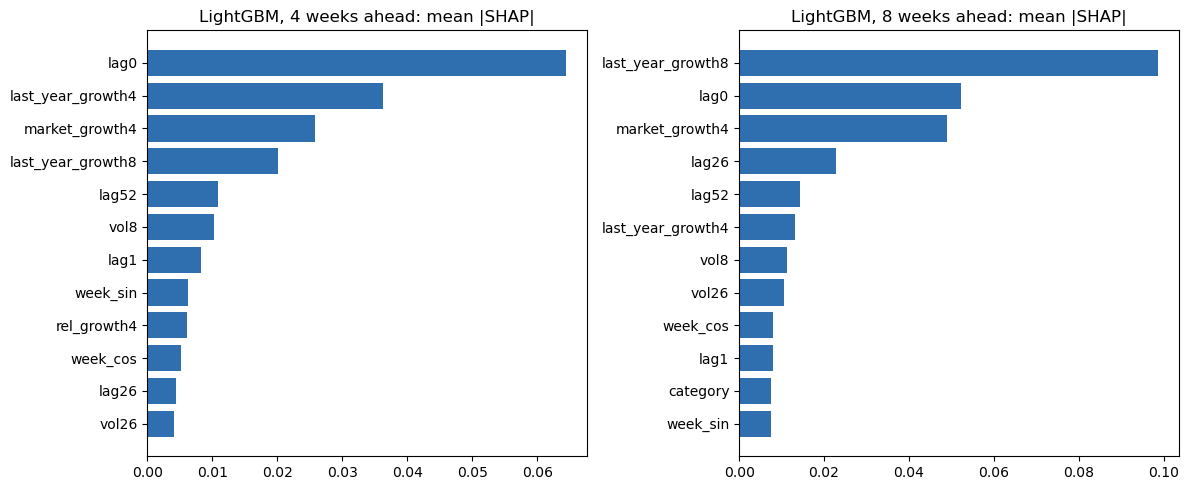

In [62]:
imp_rows, coef_rows = [], []
for h in HORIZONS:
    d = data[h]
    T = pd.Timestamp(TEST_START)
    train = d[(d["target_date"] <= T) & d["actual"].notna()]
    test = d[d["date"] >= T]

    p = best[("lightgbm", h)]
    model = lgb.LGBMRegressor(n_estimators=p["n_estimators"], learning_rate=p["learning_rate"],
                              num_leaves=p["num_leaves"], min_child_samples=p["min_child_samples"],
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              random_state=0, verbose=-1)
    model.fit(train[LGBM_FEATURES], train["target"])
    shap = model.predict(test[LGBM_FEATURES], pred_contrib=True)[:, :-1]   # last column = base value
    for f, v in zip(LGBM_FEATURES, np.abs(shap).mean(axis=0)):
        imp_rows.append({"model": "lightgbm", "horizon": h, "feature": f, "mean_abs_shap": v})

    logit = make_pipeline(StandardScaler(),
                          LogisticRegression(C=best[("logistic", h)]["C"], class_weight="balanced", max_iter=2000))
    logit.fit(train[LOGIT_FEATURES], train["actually_rose"])
    for f, c in zip(LOGIT_FEATURES, logit[-1].coef_[0]):
        coef_rows.append({"model": "logistic", "horizon": h, "feature": f, "coefficient": c})

importance = pd.DataFrame(imp_rows).sort_values(["horizon", "mean_abs_shap"], ascending=[True, False])
coefs = pd.DataFrame(coef_rows).sort_values(["horizon", "coefficient"], key=lambda s: s.abs() if s.name == "coefficient" else s,
                                            ascending=[True, False])
importance.to_csv(os.path.join(OUT_DIR, "feature_importance_shap.csv"), index=False)
coefs.to_csv(os.path.join(OUT_DIR, "logistic_coefficients.csv"), index=False)

fig, axes = plt.subplots(1, len(HORIZONS), figsize=(12, 5))
for ax, h in zip(np.atleast_1d(axes), HORIZONS):
    s = importance[importance["horizon"] == h].head(12).iloc[::-1]
    ax.barh(s["feature"], s["mean_abs_shap"], color="#2F6FB0")
    ax.set_title(f"LightGBM, {h} weeks ahead: mean |SHAP|")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "feature_importance_shap.png"), dpi=150)
plt.show()

## 11. Forecast graphs

Actual 4-week average vs. the LightGBM forecast (average of the seeds) during the final test, for a few styles.

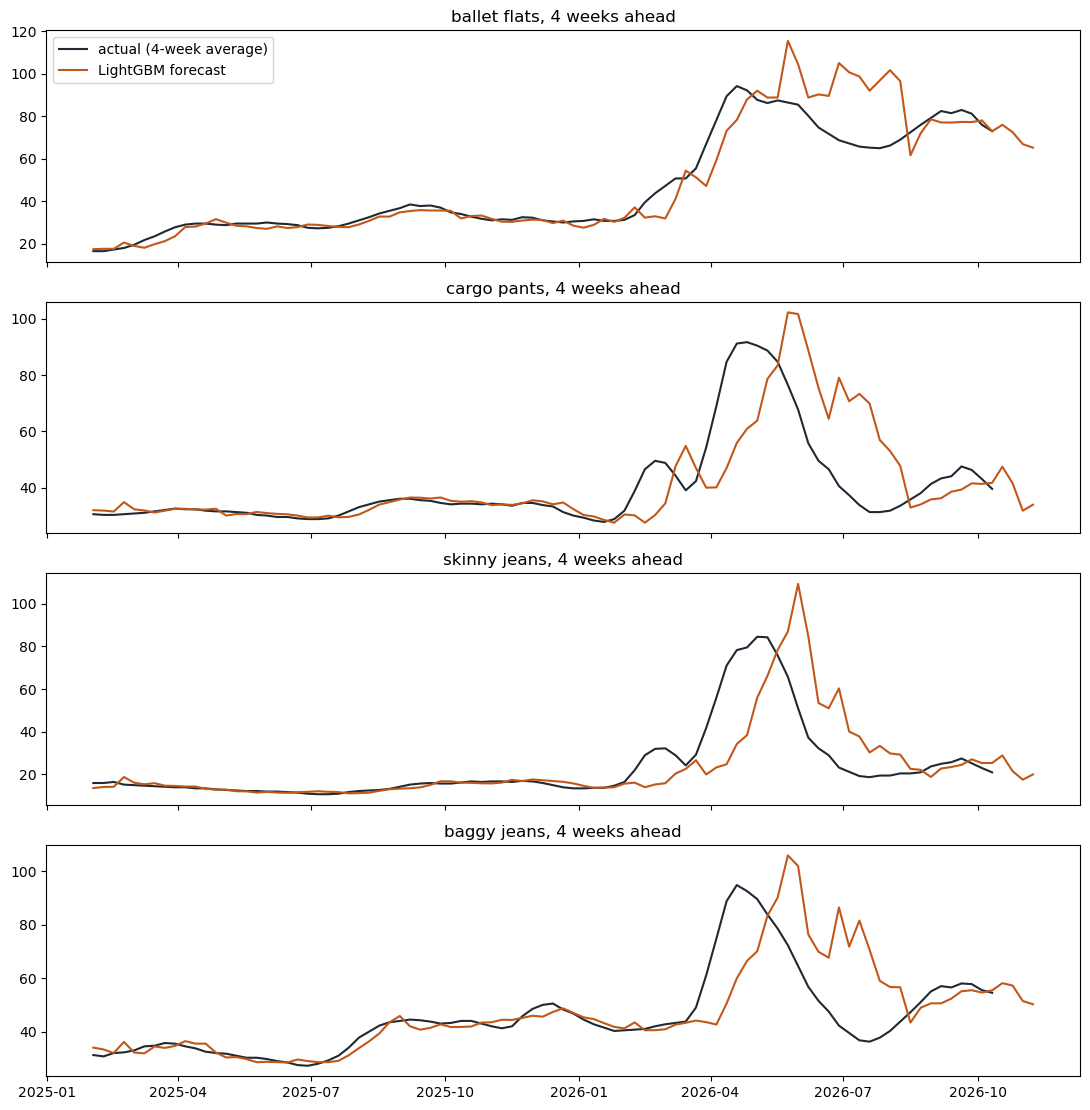

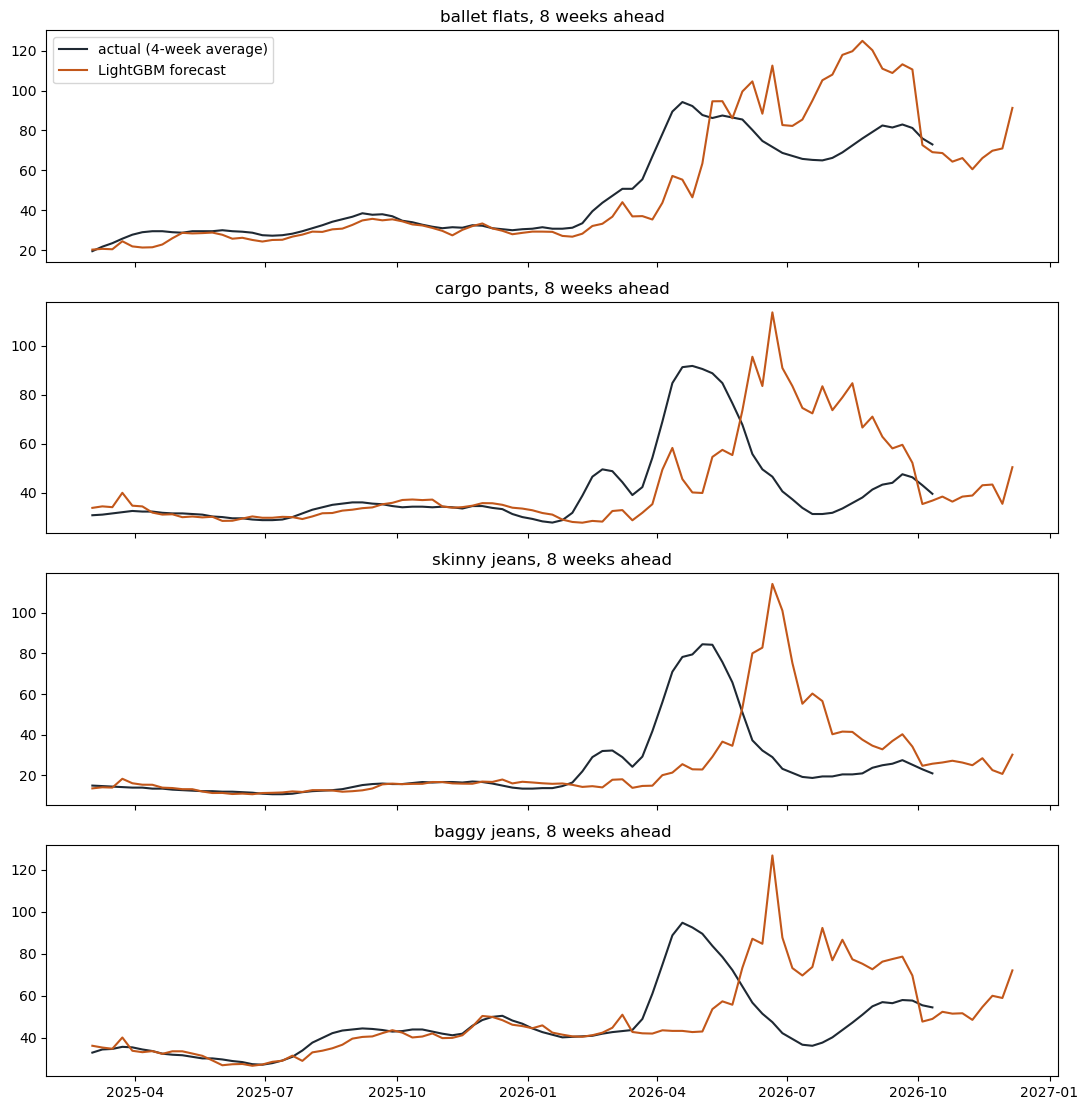

In [63]:
SHOW = [k for k in ["ballet flats", "cargo pants", "skinny jeans", "baggy jeans"] if k in wide.columns] \
       or list(wide.columns[:4])

for h in HORIZONS:
    fig, axes = plt.subplots(len(SHOW), 1, figsize=(11, 2.8 * len(SHOW)), sharex=True)
    for ax, item in zip(np.atleast_1d(axes), SHOW):
        r = rank[(rank["item"] == item) & (rank["horizon"] == h)].copy()
        r["target_week"] = r["date"] + pd.Timedelta(weeks=h)   # plot against the week being forecast
        ax.plot(r["target_week"], r["actual"], label="actual (4-week average)", color="#1F2933")
        ax.plot(r["target_week"], r["predicted"], label="LightGBM forecast", color="#C2571A")
        ax.set_title(f"{item}, {h} weeks ahead")
    np.atleast_1d(axes)[0].legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"forecasts_h{h}.png"), dpi=150)
    plt.show()

## 12. Files saved

| File | What it contains |
| --- | --- |
| `predictions_lightgbm.csv` | LightGBM forecasts, validation years and final test, seeds 0-4 |
| `predictions_logistic.csv` | Logistic regression rising probabilities, validation years and final test |
| `tuning_results_lightgbm_logistic.csv` | Every setting tried, per validation year |
| `metrics_comparison.csv` | Scores of all models in the folder, including Person 1's |
| `rankings_weekly.csv` | Weekly ranking of all styles by predicted growth (for the app) |
| `feature_importance_shap.csv` | LightGBM mean absolute SHAP value per input |
| `logistic_coefficients.csv` | Logistic regression coefficients |
| `figures/` | Forecast graphs and the feature-importance chart |
| `metrics_test_spike_check.csv` | Final-test scores for 2025 only and without the spike weeks |
| `metrics_fair_comparison.csv` | Comparison with Person 1's models on the same rows |

## 13. Final test without the 2026 spike

In [ ]:

p = preds[(preds["period"] == "test") & preds["actual"].notna()].copy()
p["target_date"] = p["date"] + pd.to_timedelta(p["horizon"] * 7, unit="D")

def in_spike(s):
    return (s >= "2026-02-01") & (s <= "2026-05-31")

versions = {
    "test_2025_only": p[p["target_date"] < "2026-01-01"],
    "test_without_spike": p[~in_spike(p["date"]) & ~in_spike(p["target_date"])
                            & ~in_spike(p["target_date"] - pd.Timedelta(days=21))],
}
extra = pd.concat([evaluate(v.assign(period=name)) for name, v in versions.items()])
extra.to_csv(os.path.join(OUT_DIR, "metrics_test_spike_check.csv"), index=False)
extra.groupby(["period", "horizon", "model"]).mean(numeric_only=True).round(3)

mae   mase  direction_acc  precision  \
period             horizon model                                              
test_2025_only     4       lightgbm  1.762  0.594          0.764      0.715   
                           logistic    NaN    NaN            NaN      0.394   
                   8       lightgbm  2.718  0.561          0.783      0.768   
                           logistic    NaN    NaN            NaN      0.586   
test_without_spike 4       lightgbm  4.104  0.978          0.717      0.373   
                           logistic    NaN    NaN            NaN      0.347   
                   8       lightgbm  5.835  0.964          0.743      0.592   
                           logistic    NaN    NaN            NaN      0.536   

                                     recall     f1  precision_at_5  \
period             horizon model                                     
test_2025_only     4       lightgbm   0.414  0.525           0.671   
                           logistic   0.798  0.527           0.625   
                   8       lightgbm   0.560  0.648           0.881   
                           logistic   0.794  0.675           0.836   
test_without_spike 4       lightgbm   0.366  0.370           0.622   
                           logistic   0.798  0.484           0.573   
                   8       lightgbm   0.657  0.623           0.801   
                           logistic   0.819  0.648           0.763   

                                     precision_at_10  precision_at_20  \
period             horizon model                                        
test_2025_only     4       lightgbm            0.579            0.422   
                           logistic            0.565            0.427   
                   8       lightgbm            0.842            0.740   
                           logistic            0.802            0.739   
test_without_spike 4       lightgbm            0.543            0.412   
                           logistic            0.527            0.419   
                   8       lightgbm            0.761            0.678   
                           logistic            0.737            0.681   

                                        rows  pr_auc  
period             horizon model                      
test_2025_only     4       lightgbm  31325.0     NaN  
                           logistic   6265.0   0.575  
                   8       lightgbm  28700.0     NaN  
                           logistic   5740.0   0.753  
test_without_spike 4       lightgbm  43895.0     NaN  
                           logistic   8779.0   0.393  
                   8       lightgbm  38630.0     NaN  
                           logistic   7726.0   0.622

## 14. Fair comparison with Person 1
Person 1's dates are the week being forecast, so they are shifted back by the horizon, and both are scored on the same rows against the 4-week-average target.

In [ ]:
p1 = pd.read_csv(os.path.join(OUT_DIR, "predictions.csv"), parse_dates=["date"])
p1["date"] = p1["date"] - pd.to_timedelta(p1["horizon"] * 7, unit="D")   
truth = pd.concat([data[h][["date", "item", "horizon", "actual", "last4_avg"]] for h in HORIZONS])
truth = truth[truth["actual"].notna()]

p1_fair = p1.drop(columns="actual").merge(truth, on=["date", "item", "horizon"], how="inner")
p1_fair["period"] = np.where(p1_fair["period"] == "test", "test", "validation")

mine = preds[preds["model"] == "lightgbm"].copy()
mine["period"] = np.where(mine["period"] == "test", "test", "validation")
common = p1_fair[["date", "item", "horizon", "period"]].drop_duplicates()
mine_fair = mine.merge(common, on=["date", "item", "horizon", "period"], how="inner")

fair = evaluate(pd.concat([p1_fair, mine_fair], ignore_index=True))
fair.to_csv(os.path.join(OUT_DIR, "metrics_fair_comparison.csv"), index=False)
fair.sort_values(["period", "horizon", "mae"]).round(3)

,model,horizon,period,mae,mase,direction_acc,precision,recall,f1,precision_at_5,precision_at_10,precision_at_20,rows
12,last_value,4,test,6.029,0.816,0.672,0.611,0.246,0.351,0.445,0.404,0.355,12229
4,ets,4,test,6.525,0.883,0.684,0.609,0.296,0.398,0.486,0.431,0.366,12229
16,lightgbm,4,test,7.346,0.974,0.689,0.432,0.295,0.350,0.605,0.537,0.427,58515
0,avg_4w,4,test,7.393,1.000,0.030,0.000,0.000,0.000,0.065,0.097,0.107,12229
8,lasso,4,test,8.412,1.138,0.678,0.585,0.278,0.377,0.520,0.480,0.388,12229
20,ridge,4,test,8.452,1.143,0.678,0.583,0.279,0.377,0.523,0.478,0.389,12229
24,seasonal_naive,4,test,11.516,1.558,0.603,0.422,0.174,0.247,0.387,0.356,0.312,12229
14,last_value,8,test,10.588,0.951,0.580,0.567,0.140,0.225,0.456,0.434,0.421,12218
2,avg_4w,8,test,11.137,1.000,0.017,0.000,0.000,0.000,0.075,0.128,0.155,12218
6,ets,8,test,11.201,1.006,0.604,0.573,0.199,0.295,0.535,0.499,0.448,12218
